In [1]:
import pandas as pd

In [2]:
column_names = ["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE", 
                 "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV"]

house = pd.read_csv(
    r"C:\Users\Personal\Downloads\Data Set For Task-20260922T064326Z-1-001\Data Set For Task\4) house Prediction Data Set.csv",
    sep=r"\s+",
    header=None,
    names=column_names
)

In [3]:
house.info()
house.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [4]:
X = house[["RM"]]
y = house["MEDV"]

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
print(X_train.shape, X_test.shape)

(404, 1) (102, 1)


In [7]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [8]:
print("Intercept (pika ku vija pret boshtin Y):", model.intercept_)
print("Koeficienti për RM:", model.coef_[0])

Intercept (pika ku vija pret boshtin Y): -36.24631889813795
Koeficienti për RM: 9.348301406497727


In [9]:
y_pred = model.predict(X_test)

In [10]:
from sklearn.metrics import r2_score, mean_squared_error

r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("R-squared:", r2)
print("Mean Squared Error:", mse)

R-squared: 0.3707569232254778
Mean Squared Error: 46.144775347317264


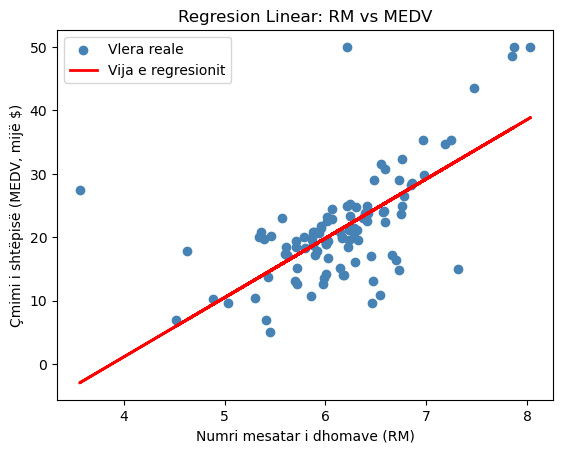

In [11]:
import matplotlib.pyplot as plt

plt.scatter(X_test, y_test, color="steelblue", label="Vlera reale")
plt.plot(X_test, y_pred, color="red", linewidth=2, label="Vija e regresionit")
plt.title("Regresion Linear: RM vs MEDV")
plt.xlabel("Numri mesatar i dhomave (RM)")
plt.ylabel("Çmimi i shtëpisë (MEDV, mijë $)")
plt.legend()
plt.savefig("regression_rm_medv.png", dpi=150, bbox_inches="tight")
plt.show()